# Лабораторная работа № 1. Численное дифференцирование

**Цель:** сравнить абсолютные погрешности пяти формул численного дифференцирования.
Для каждой из пяти функций строится отдельный график с пятью линиями.
Масштаб логарифмический по обеим осям.

$$h_n=\frac{2}{2^n},\quad n=1,\ldots,21,\qquad
E_k(h)=|D_k f(x_0;h)-f'(x_0)|.$$

**Допущение:** на фотографии точка вычисления не указана, поэтому выбираем $x_0=1$.
Самый широкий шаблон при $h=1$ использует отрезок $[-2,4]$, на котором определены
все функции. Точку можно изменить в переменной `X0`; для полного набора шагов
требуется $x_0>0$, чтобы аргумент логарифма оставался положительным.

## Аналитические производные

| Функция | Производная |
|---|---|
| $\sin(x^2)$ | $2x\cos(x^2)$ |
| $\cos(\sin x)$ | $-\sin(\sin x)\cos x$ |
| $\exp(\sin(\cos x))$ | $-\exp(\sin(\cos x))\cos(\cos x)\sin x$ |
| $\ln(x+3)$ | $1/(x+3)$ |
| $(x+3)^{0.5}$ | $1/(2\sqrt{x+3})$ |

Производные получены по правилу дифференцирования сложной функции.
Их значения в точке $x_0$ служат эталоном и вычисляются в арифметике `float64`.

## Пять формул из задания

Введём $C_a(h)=\dfrac{f(x_0+ah)-f(x_0-ah)}{2ah}$.

1. Правая разность: $D_1=\dfrac{f(x_0+h)-f(x_0)}h$.
2. Левая разность: $D_2=\dfrac{f(x_0)-f(x_0-h)}h$.
3. Центральная разность: $D_3=C_1(h)$.
4. $D_4=\dfrac43 C_1(h)-\dfrac13 C_2(h)$.
5. $D_5=\dfrac32 C_1(h)-\dfrac35 C_2(h)+\dfrac1{10} C_3(h)$.

Из разложения Тейлора:
$$C_a(h)=f'(x_0)+\frac{a^2h^2}{6}f^{(3)}(x_0)
+\frac{a^4h^4}{120}f^{(5)}(x_0)+O(h^6).$$
В четвёртой формуле сокращается член с $h^2$, в пятой — с $h^2$ и $h^4$.
Порядки погрешности усечения: **1, 1, 2, 4, 6**.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Рабочая папка может быть корнем репозитория или папкой лабораторной.
LAB_DIR = Path.cwd()
if not (LAB_DIR / "differentiation.py").exists():
    LAB_DIR = LAB_DIR / "numerical_differentiation"
sys.path.insert(0, str(LAB_DIR.resolve()))
from differentiation import calculate, plot_errors, METHOD_LABELS

X0 = 1.0
h, results = calculate(X0)
print(f"Точка x₀ = {X0:g}; число шагов: {len(h)}")
print(f"h_min = {h.min():.12g}; h_max = {h.max():g}")
for result in results:
    print(f"{result['slug']}: f′(x₀) = {result['exact']:.16g}")

Точка x₀ = 1; число шагов: 21
h_min = 9.53674316406e-07; h_max = 1
sin_x2: f′(x₀) = 1.08060461173628
cos_sin_x: f′(x₀) = -0.4028624430528535
exp_sin_cos_x: f′(x₀) = -1.206977703979914
log_x_plus_3: f′(x₀) = 0.25
sqrt_x_plus_3: f′(x₀) = 0.25


## Графики абсолютной погрешности

Каждая ячейка создаёт отдельную фигуру с пятью линиями.
Шаг возрастает слева направо, поэтому уменьшение шага соответствует движению **влево**.
Данные отображаются без сглаживания. Нулевые ошибки, если они возникнут,
пропускаются только на графике: $\log 0$ не определён.
Рисунки также сохраняются в `figures/` в формате PNG.

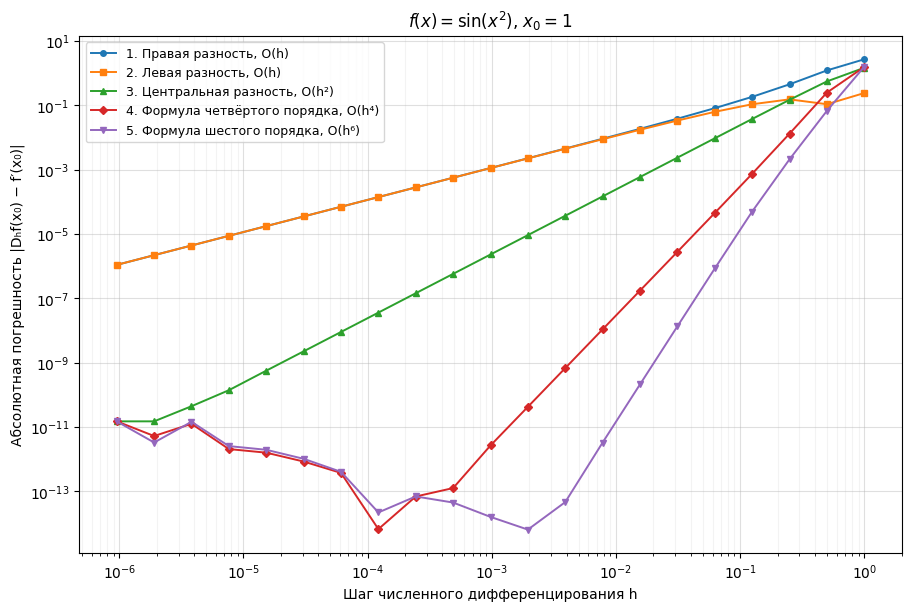

In [2]:
fig = plot_errors(h, results[0], x=X0, output_dir=LAB_DIR / "figures")
plt.show()
plt.close(fig)

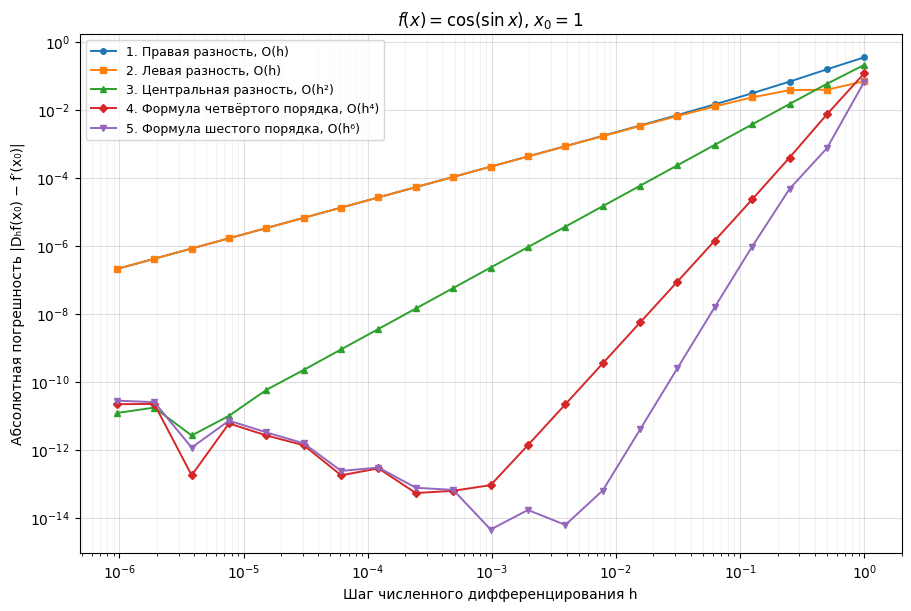

In [3]:
fig = plot_errors(h, results[1], x=X0, output_dir=LAB_DIR / "figures")
plt.show()
plt.close(fig)

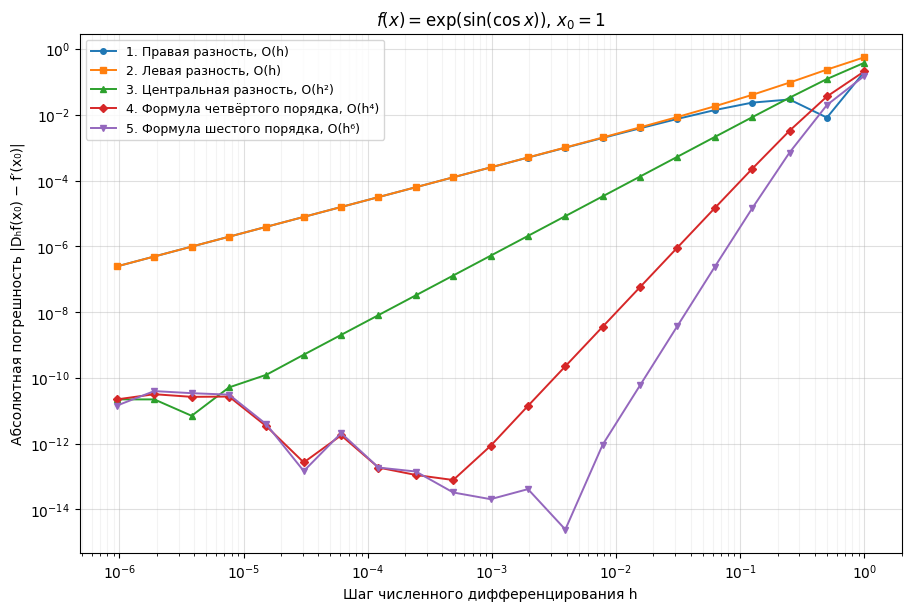

In [4]:
fig = plot_errors(h, results[2], x=X0, output_dir=LAB_DIR / "figures")
plt.show()
plt.close(fig)

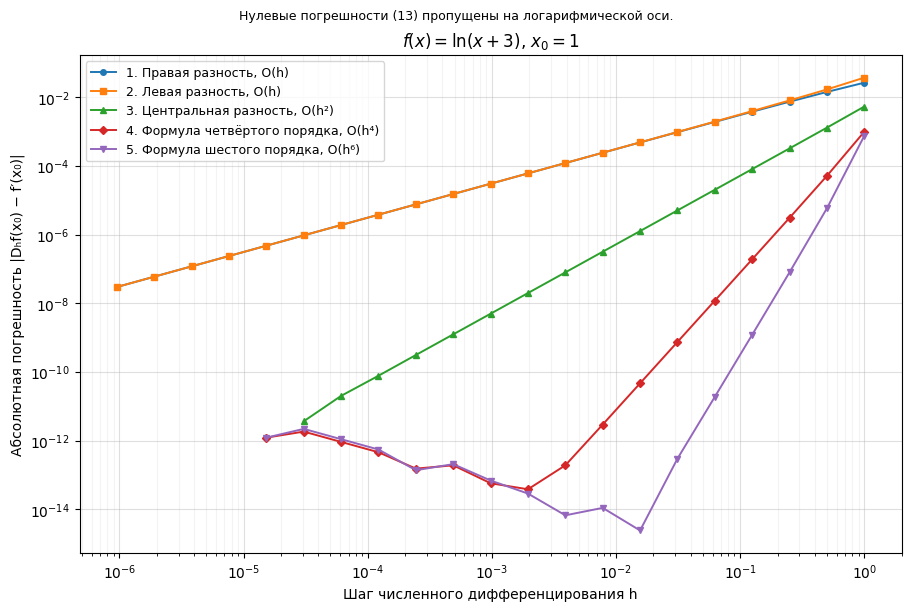

In [5]:
fig = plot_errors(h, results[3], x=X0, output_dir=LAB_DIR / "figures")
plt.show()
plt.close(fig)

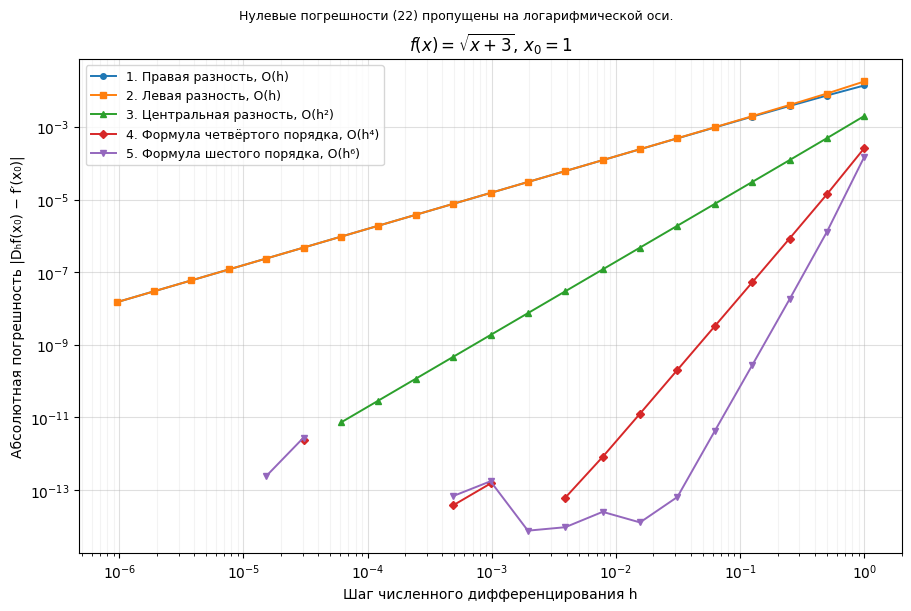

In [6]:
fig = plot_errors(h, results[4], x=X0, output_dir=LAB_DIR / "figures")
plt.show()
plt.close(fig)

## Минимальные погрешности

Для каждой пары «функция — метод» найдём наименьшую вычисленную погрешность
среди 21 заданного шага. Это дискретный минимум, а не непрерывная оптимизация.
Результаты на уровне машинной точности могут зависеть от платформы.

In [7]:
for result in results:
    print(result["slug"])
    print(f"{'Метод':48s} {'Минимальная ошибка':>19s} {'Шаг h':>14s}")
    for label, errors in zip(METHOD_LABELS, result["errors"]):
        index = int(np.argmin(errors))
        print(f"{label:48s} {errors[index]:19.6e} {h[index]:14.6e}")
    print()

sin_x2
Метод                                             Минимальная ошибка          Шаг h
1. Правая разность, O(h)                                1.089721e-06   9.536743e-07
2. Левая разность, O(h)                                 1.089691e-06   9.536743e-07
3. Центральная разность, O(h²)                          1.492406e-11   1.907349e-06
4. Формула четвёртого порядка, O(h⁴)                    6.661338e-15   1.220703e-04
5. Формула шестого порядка, O(h⁶)                       6.439294e-15   1.953125e-03

cos_sin_x
Метод                                             Минимальная ошибка          Шаг h
1. Правая разность, O(h)                                2.063342e-07   9.536743e-07
2. Левая разность, O(h)                                 2.063581e-07   9.536743e-07
3. Центральная разность, O(h²)                          2.600253e-12   3.814697e-06
4. Формула четвёртого порядка, O(h⁴)                    5.245804e-14   2.441406e-04
5. Формула шестого порядка, O(h⁶)                       4.

## Выводы

- Пока доминирует погрешность усечения, уменьшение шага снижает ошибку.
  Зависимость $E\approx Ch^p$ на логарифмическом графике имеет наклон $p$.
  Ожидаемые порядки пяти формул: $1,1,2,4,6$.
- Формулы высоких порядков достигают малых погрешностей при более крупных шагах.
  На малых шагах вычитание близких значений функции и деление на $h$ усиливают
  ошибки округления, и преимущество высокого порядка уменьшается.
- Модель $E(h)\approx C_1h^p+C_2\varepsilon/h$, где
  $\varepsilon\approx2.22\cdot10^{-16}$ для `float64`, объясняет минимум ошибки,
  а затем её рост или колебания. Она не описывает каждый отдельный отсчёт.
- Наименьший шаг не обязательно даёт наилучший результат. Лучший из исследованных
  шагов зависит от функции и метода; значения приведены в таблице.
- Нулевая разность с эталоном в машинной арифметике не означает математически
  точного дифференцирования. Аналитический эталон тоже вычисляется с округлением.